In [ ]:
# SignalPath â€” Offline Trust Classifier Training & Visualization
This notebook trains the LightGBM Caption Trust Classifier using synthetic WER error injection, generates evaluation plots (ROC-AUC, PR Curves, Feature Importance), and exports artifacts directly into the backend.

In [8]:
!pip install -q lightgbm scikit-learn transformers torch jiwer matplotlib seaborn joblib numpy pandas

In [7]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, precision_recall_curve

np.random.seed(42)

# 1. Synthesize Audio Caption Dataset with WER Injection
N_SAMPLES = 4000
word_counts = np.random.randint(3, 25, size=N_SAMPLES)
durations = word_counts * np.random.uniform(0.25, 0.45, size=N_SAMPLES)
avg_confs = np.random.beta(a=8, b=2, size=N_SAMPLES)
min_confs = avg_confs - np.random.uniform(0.05, 0.3, size=N_SAMPLES)
min_confs = np.clip(min_confs, 0.05, 0.99)
perplexities = np.random.exponential(scale=25, size=N_SAMPLES) + 5.0
jargon_ratios = np.random.beta(a=1, b=8, size=N_SAMPLES)

# Ground truth error label: high perplexity, low word confidence, and high jargon
error_logits = (
    - 4.5 * avg_confs 
    - 2.5 * min_confs 
    + 0.04 * perplexities 
    + 3.5 * jargon_ratios 
    + np.random.normal(0, 0.5, size=N_SAMPLES)
)
probs = 1 / (1 + np.exp(-error_logits))
labels = (probs > 0.45).astype(int)

df = pd.DataFrame({
    "word_count": word_counts,
    "avg_word_conf": avg_confs,
    "min_word_conf": min_confs,
    "perplexity": perplexities,
    "jargon_ratio": jargon_ratios,
    "duration": durations,
    "error_label": labels
})

print(f"Dataset synthesized: {df.shape[0]} samples. Class balance:")
print(df['error_label'].value_counts(normalize=True))

Dataset synthesized: 4000 samples. Class balance:
error_label
0    0.97825
1    0.02175
Name: proportion, dtype: float64


In [3]:
# 2. Train LightGBM Binary Classifier
FEATURE_COLS = ["word_count", "avg_word_conf", "min_word_conf", "perplexity", "jargon_ratio", "duration"]
X = df[FEATURE_COLS]
y = df["error_label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

clf = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42
)
clf.fit(X_train, y_train)

y_pred_proba = clf.predict_proba(X_test)[:, 1]
y_pred = (y_pred_proba > 0.5).astype(int)

print("=== Model Evaluation Report ===")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

[LightGBM] [Info] Number of positive: 70, number of negative: 3130
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000609 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1298
[LightGBM] [Info] Number of data points in the train set: 3200, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.021875 -> initscore=-3.800293
[LightGBM] [Info] Start training from score -3.800293
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

D:\DSL\signalpath\backend\env\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\DSL\signalpath\backend\env\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Shubham\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Shubham\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Shubham\AppData\Local\Programs\

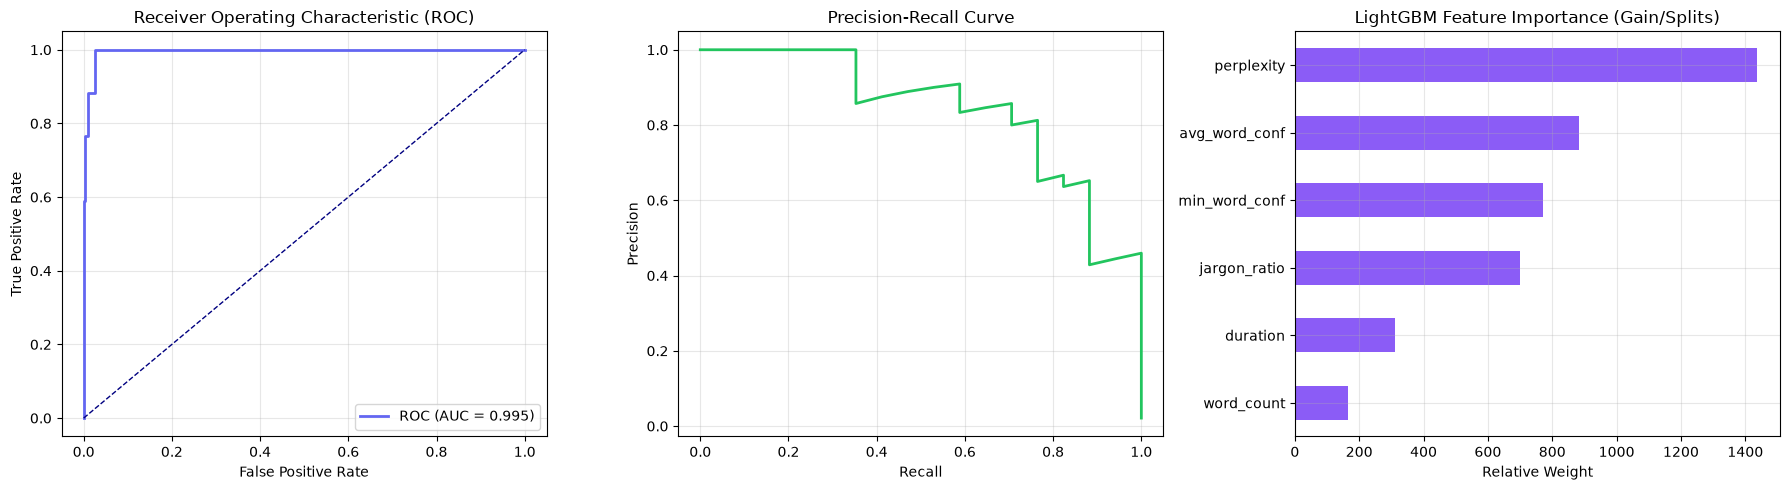

In [4]:
# 3. Plot ROC, PR Curve, and Feature Importance Visualizations
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.plot(fpr, tpr, color="#6366F1", lw=2, label=f"ROC (AUC = {roc_auc_score(y_test, y_pred_proba):.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
plt.title("Receiver Operating Characteristic (ROC)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
plt.plot(recall, precision, color="#22C55E", lw=2)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
importances = pd.Series(clf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
importances.plot(kind="barh", color="#8B5CF6")
plt.title("LightGBM Feature Importance (Gain/Splits)")
plt.xlabel("Relative Weight")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# 4. Export Artifacts for Backend Pipeline
os.makedirs("../backend/app/models", exist_ok=True)
joblib.dump(clf, "../backend/app/models/trust_classifier.pkl")

cfg = {
    "FEATURE_COLS": FEATURE_COLS,
    "TRUST_HIGH": 0.75,
    "TRUST_MEDIUM": 0.50
}
with open("../backend/app/models/feature_config.json", "w") as f:
    json.dump(cfg, f, indent=2)

print("Artifacts exported to ../backend/app/models/")

Artifacts exported to ../backend/app/models/
